# P1 – Network and Louvain communities (fixed version)

Fixes compared with the first notebook:
1. only coordinators and participants (the `role` column)
2. agreed country list (no Turkey; Ukraine, Moldova, Western Balkans added)
3. Newman weight uses the full consortium size
4. CSVs read with `skipinitialspace` and `escapechar`
5. no connected-components consensus: best of 20 Louvain runs + stability

In [1]:
# Imports
import time
from collections import Counter
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import normalized_mutual_info_score as nmi
from sklearn.metrics import adjusted_mutual_info_score as ami

import networkx as nx
from networkx.algorithms.community import modularity
import community as community_louvain
from infomap import Infomap
from sklearn.metrics import normalized_mutual_info_score
from networkx.algorithms import bipartite
from ANS_06_utils import graph_summary

In [2]:
# 1. Load the data
# Netzschleuder CSVs have spaces after the commas and escaped quotes inside names
df_nodes = pd.read_csv("nodes.csv", skipinitialspace=True, escapechar="\\", low_memory=False)
df_edges = pd.read_csv("edges.csv", skipinitialspace=True, escapechar="\\")
df_nodes.columns = [c.lstrip("#").strip() for c in df_nodes.columns]   # '# index' -> 'index'
df_edges.columns = [c.lstrip("#").strip() for c in df_edges.columns]   # '# source' -> 'source'
# in edges.csv: source = organization, target = project

In [24]:
df_nodes.head()

,index,is_project,name,id,latitude,longitude,euroscivoc,acronym,status,start_date,...,grant_doi,keywords,sme,activity_type,city,post_code,country,nuts_code,url,_pos
0,0,1,Full spectrum SOLar Direct Air Capture & conve...,101069359,NaN,NaN,natural sciences/chemical sciences/electrochem...,SolDAC,SIGNED,1661990400,...,10.3030/101069359,"zero-carbon, solar energy, air mining, Negativ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,"array([-22.19285885, 116.25605589])"
1,1,1,Artificial PHOTOsynthesis to produce FUELs and...,101069357,NaN,NaN,engineering and technology/environmental engin...,Photo2Fuel,SIGNED,1661990400,...,10.3030/101069357,solar energy; bacteria; archaea; solar fuels; ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"array([-23.54534475, 117.30806949])"
2,2,1,Bridging Organizations and marginalized commun...,101069586,NaN,NaN,social sciences/sociology/governance|social sc...,BOLSTER,SIGNED,1661990400,...,10.3030/101069586,Transition strategies; Participation; Marginal...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"array([-18.23962287, 118.80845353])"
3,3,1,NCPS NETwork for the GREEN transition in clima...,101069604,NaN,NaN,NaN,GREENET,SIGNED,1656633600,...,10.3030/101069604,"Competence development, Capacity building, CL5...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,"array([-27.77547463, 109.60801029])"
4,4,1,"Social Sciences and Humanities for Climate, En...",101069529,NaN,NaN,social sciences/economics and business/economi...,SSH CENTRE,SIGNED,1661990400,...,10.3030/101069529,Transitions; Transdisciplinary; Epistemic cult...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"array([-26.48000805, 108.76182656])"


In [5]:
# 2. Filters
EU27 = ["AT", "BE", "BG", "HR", "CY", "CZ", "DK", "EE", "FI", "FR", "DE", "EL", "HU", "IE",
        "IT", "LV", "LT", "LU", "MT", "NL", "PL", "PT", "RO", "SK", "SI", "ES", "SE"]
european_countries = EU27 + ["NO", "IS", "LI", "CH", "UK",            # EFTA + UK
                             "AL", "BA", "ME", "MK", "RS", "XK",      # Western Balkans
                             "UA", "MD", "FO", "VA", "MC", "GI"]      # other European
valid_funding_schemes = ["HORIZON-RIA", "HORIZON-IA", "HORIZON-JU-RIA", "HORIZON-JU-IA"]
valid_activity_types = ["HES", "REC"]
valid_roles = ["coordinator", "participant"]

projects = df_nodes[(df_nodes["is_project"] == 1)
                    & df_nodes["funding_scheme"].isin(valid_funding_schemes)]
orgs = df_nodes[(df_nodes["is_project"] == 0)
                & df_nodes["activity_type"].isin(valid_activity_types)
                & df_nodes["country"].isin(european_countries)]

# coordinators and participants of the kept projects (all organization types and countries)
memberships = df_edges[df_edges["role"].isin(valid_roles)
                       & df_edges["target"].isin(projects["index"])]

# Newman weight needs the real consortium size: all coordinators + participants of the project
consortium_size = memberships.groupby("target")["source"].nunique()

# keep European universities and research organizations with at least 3 projects
memberships = memberships[memberships["source"].isin(orgs["index"])]
n_projects = memberships.groupby("source")["target"].nunique()
final_org_ids = set(n_projects[n_projects >= 3].index)
memberships = memberships[memberships["source"].isin(final_org_ids)]

print(f"Organizations: {len(final_org_ids)}, projects: {memberships['target'].nunique()}")

Organizations: 1655, projects: 4856


In [7]:
# 3. Newman-weighted projection: each project adds 1/(n-1) to every pair of its members
org_net = nx.Graph()
for project, members in memberships.groupby("target")["source"]:
    members = sorted(set(members))
    if len(members) < 2:                    # a project with one kept member adds no edge
        continue
    w = 1.0 / (consortium_size[project] - 1)
    for u, v in itertools.combinations(members, 2):
        if org_net.has_edge(u, v):
            org_net[u][v]["weight"] += w
            org_net[u][v]["n_joint"] += 1
        else:
            org_net.add_edge(u, v, weight=w, n_joint=1)

for u, v, d in org_net.edges(data=True):
    d["dist"] = 1.0 / d["weight"]          # distance for betweenness (P2)

graph_summary(org_net)

Directed: False
Weighted: True
Nodes: 1655
Edges: 70779
Density: 0.05171314071535817
Number of components: 1


In [8]:
# 4. Node labels: name, country, type, projects, coordinated projects, topic
def second_level_fields(s):
    """'natural sciences/chemical sciences/electrochemistry|...' -> ['natural sciences', ...]"""
    if not isinstance(s, str):
        return []
    return list({x.split("/")[1] for x in s.split("|") if x.count("/") >= 1})


project_fields = projects.set_index("index")["euroscivoc"].apply(second_level_fields)
fields_long = memberships.assign(field=memberships["target"].map(project_fields)).explode("field")
topic = fields_long.dropna(subset=["field"]).groupby("source")["field"].agg(lambda s: s.mode()[0])
n_coord = memberships[memberships["role"] == "coordinator"].groupby("source").size()

info = orgs.set_index("index")
labels = pd.DataFrame({
    "name": info["name"],
    "country": info["country"],
    "org_type": info["activity_type"],
    "n_projects": n_projects,
    "n_coordinated": n_coord,
    "topic": topic,
}).loc[list(org_net.nodes())]
labels["n_coordinated"] = labels["n_coordinated"].fillna(0).astype(int)
labels["topic"] = labels["topic"].fillna("unknown")
nx.set_node_attributes(org_net, labels.to_dict("index"))
labels.head()

,name,country,org_type,n_projects,n_coordinated,topic
23957,THE UNIVERSITY COURT OF THE UNIVERSITY OF ST A...,UK,HES,14.0,1,biological sciences
23958,FUNDACIO INSTITUT DE RECERCA EN ENERGIA DE CAT...,ES,REC,32.0,2,environmental engineering
23959,UNIVERSIDAD DE LLEIDA,ES,HES,9.0,0,environmental engineering
23960,CONSIGLIO NAZIONALE DELLE RICERCHE,IT,REC,279.0,70,computer and information sciences
23961,THE UNIVERSITY OF EDINBURGH,UK,HES,61.0,57,computer and information sciences


In [9]:
# 5. Louvain: 20 runs, keep the one with the highest modularity
runs = [community_louvain.best_partition(org_net, weight="weight", random_state=s) for s in range(20)]
Q = [community_louvain.modularity(r, org_net, weight="weight") for r in runs]
best_seed = int(np.argmax(Q))
partition = runs[best_seed]
labels["community"] = pd.Series(partition)

print(f"Best run: seed {best_seed}, {len(set(partition.values()))} communities, Q = {Q[best_seed]:.4f}")
print(f"Modularity over 20 runs: mean {np.mean(Q):.4f}, min {min(Q):.4f}, max {max(Q):.4f}")

Best run: seed 15, 5 communities, Q = 0.2459
Modularity over 20 runs: mean 0.2438, min 0.2416, max 0.2459


In [10]:
# 6. Stability: compare all pairs of runs
nodes_sorted = sorted(org_net.nodes())
vecs = [[r[n] for n in nodes_sorted] for r in runs]
pairs = list(itertools.combinations(vecs, 2))
print(f"Mean NMI between runs: {np.mean([nmi(a, b) for a, b in pairs]):.3f}")
print(f"Mean AMI between runs: {np.mean([ami(a, b) for a, b in pairs]):.3f}")

Mean NMI between runs: 0.682
Mean AMI between runs: 0.681


In [11]:
# 7. Resolution sweep (robustness): 10 runs per resolution
rows = []
for res in [0.5, 0.75, 1.0, 1.25, 1.5]:
    rr = [community_louvain.best_partition(org_net, weight="weight", resolution=res, random_state=s)
          for s in range(10)]
    vv = [[r[n] for n in nodes_sorted] for r in rr]
    rows.append({
        "resolution": res,
        "communities (median)": int(np.median([len(set(r.values())) for r in rr])),
        "modularity (mean)": round(np.mean([community_louvain.modularity(r, org_net) for r in rr]), 3),
        "stability AMI": round(np.mean([ami(a, b) for a, b in itertools.combinations(vv, 2)]), 3),
    })
sweep = pd.DataFrame(rows)
sweep

,resolution,communities (median),modularity (mean),stability AMI
0,0.50,240,0.087,0.201
1,0.75,7,0.232,0.610
2,1.00,5,0.244,0.675
3,1.25,12,0.225,0.621
4,1.50,21,0.200,0.586


In [12]:
# 8. Community profiles: size, top topics, top countries
profiles = []
for c, grp in labels.groupby("community"):
    top_topics = grp["topic"].value_counts(normalize=True).head(3)
    top_countries = grp["country"].value_counts(normalize=True).head(3)
    profiles.append({
        "community": c,
        "size": len(grp),
        "top topics": ", ".join(f"{t} {v:.0%}" for t, v in top_topics.items()),
        "top countries": ", ".join(f"{t} {v:.0%}" for t, v in top_countries.items()),
        "n countries": grp["country"].nunique(),
    })
profiles = pd.DataFrame(profiles).sort_values("size", ascending=False)
profiles

,community,size,top topics,top countries,n countries
1,1,575,"computer and information sciences 31%, environ...","ES 18%, DE 11%, IT 9%",32
2,2,474,"clinical medicine 24%, computer and informatio...","DE 14%, ES 11%, IT 10%",32
4,4,346,"agriculture, forestry, and fisheries 41%, biol...","DE 15%, ES 13%, IT 7%",33
0,0,257,"earth and related environmental sciences 29%, ...","FR 17%, DE 11%, IT 9%",31
3,3,3,"biological sciences 67%, environmental enginee...","IT 33%, FR 33%, PL 33%",3


In [13]:
# 9. What organizes the communities? AMI with topic / country / type vs shuffled labels
rng = np.random.default_rng(0)
comm = labels["community"].values
rows = []
for col in ["topic", "country", "org_type"]:
    lab = labels[col].values
    real = ami(lab, comm) # maybe we should reason why don't we use NMI
    shuffled = [ami(rng.permutation(lab), comm) for _ in range(200)]
    rows.append({"label": col, "AMI": round(real, 3),
                 "shuffled mean": round(np.mean(shuffled), 4),
                 "shuffled 99th pct": round(np.percentile(shuffled, 99), 4)})
organizing = pd.DataFrame(rows)
organizing         

,label,AMI,shuffled mean,shuffled 99th pct
0,topic,0.190,0.0001,0.0049
1,country,0.016,0.0003,0.0052
2,org_type,0.008,0.0000,0.0031


In [14]:
# 10. Niche communities: Louvain again inside each big community
niche = {}
for c, grp in labels.groupby("community"):
    sub = org_net.subgraph(grp.index)
    if sub.number_of_edges() == 0:
        niche.update({n: f"{c}.0" for n in grp.index})
        continue
    p = community_louvain.best_partition(sub, weight="weight", random_state=0)
    niche.update({n: f"{c}.{k}" for n, k in p.items()})
labels["niche"] = pd.Series(niche)
print(f"{labels['niche'].nunique()} niche communities")

26 niche communities


In [15]:
# 11. Save files for P2, P3 and P4
nx.to_pandas_edgelist(org_net).to_csv("network_edges.csv", index=False)       # source, target, weight, n_joint, dist
labels.rename_axis("org").to_csv("communities.csv")                            # labels + community + niche
profiles.to_csv("community_profiles.csv", index=False)
organizing.to_csv("ami_topic_country_type.csv", index=False)
sweep.to_csv("resolution_sweep.csv", index=False)

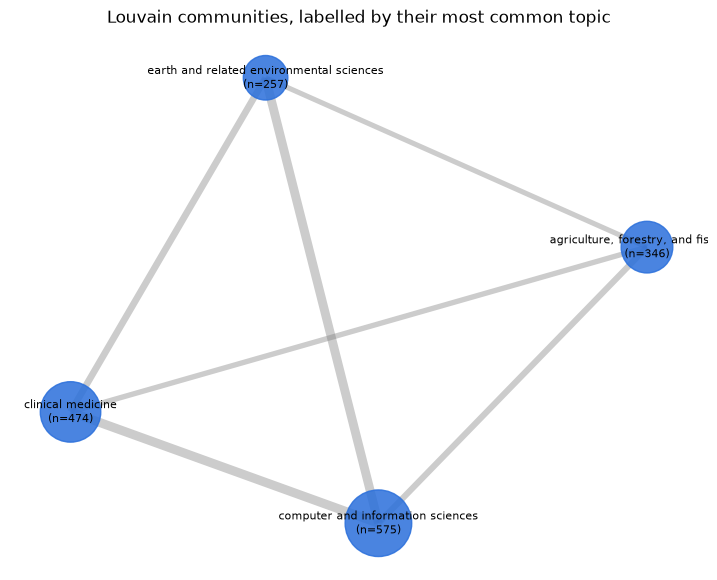

In [16]:
# 12. Figure: one node per community (instead of the full hairball)
C = nx.Graph()
for c, grp in labels.groupby("community"):
    if len(grp) >= 10:                      # skip tiny communities
        C.add_node(c, size=len(grp), topic=grp["topic"].value_counts().index[0])
for u, v, d in org_net.edges(data=True):
    cu, cv = partition[u], partition[v]
    if cu != cv and cu in C and cv in C:
        old = C[cu][cv]["weight"] if C.has_edge(cu, cv) else 0
        C.add_edge(cu, cv, weight=old + d["weight"])

pos = nx.spring_layout(C, weight="weight", seed=1)
wmax = max(d["weight"] for _, _, d in C.edges(data=True))
plt.figure(figsize=(9, 7))
nx.draw_networkx_edges(C, pos, width=[0.5 + 6 * d["weight"] / wmax for _, _, d in C.edges(data=True)],
                       alpha=0.4, edge_color="gray")
nx.draw_networkx_nodes(C, pos, node_size=[4 * C.nodes[c]["size"] for c in C], node_color="#2a6fdb", alpha=0.85)
nx.draw_networkx_labels(C, pos, {c: f"{C.nodes[c]['topic']}\n(n={C.nodes[c]['size']})" for c in C}, font_size=8)
plt.title("Louvain communities, labelled by their most common topic")
plt.axis("off")
plt.show()

In [ ]:
plt.figure(figsize=(10, 10))

pos_karate = nx.spring_layout(org_net, k=0.5, seed=2)

nx.draw_networkx_edges(org_net, pos_karate, alpha=0.05, edge_color="gray")
nx.draw_networkx_nodes(
    org_net,
    pos_karate,
    node_size=35,
    node_color=list(cl_louvain.values()),
    cmap=plt.cm.Set3,
)

plt.title("Louvain communities on the organization network")
plt.axis("off") 
plt.show()